In [53]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
from pathlib import Path

import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping

In [54]:
train_path = '/kaggle/input/datasets/misrakahmed/vegetable-image-dataset/Vegetable Images/train'
test_path = '/kaggle/input/datasets/misrakahmed/vegetable-image-dataset/Vegetable Images/test'
valid_path = '/kaggle/input/datasets/misrakahmed/vegetable-image-dataset/Vegetable Images/validation'
train_path

'/kaggle/input/datasets/misrakahmed/vegetable-image-dataset/Vegetable Images/train'

In [55]:
## Part 3: Count Images in Each Class
classs = os.listdir(train_path)
classs

['Bean',
 'Bitter_Gourd',
 'Bottle_Gourd',
 'Brinjal',
 'Broccoli',
 'Cabbage',
 'Capsicum',
 'Carrot',
 'Cauliflower',
 'Cucumber',
 'Papaya',
 'Potato',
 'Pumpkin',
 'Radish',
 'Tomato']

In [56]:
# this is the function
def count_images_per_class(dataset_path):
    counts = {}
    for class_name in sorted(os.listdir(dataset_path)):
        class_path = os.path.join(dataset_path, class_name)
        if os.path.isdir(class_path):
            counts[class_name] = len(os.listdir(class_path))
    return counts

## Part 4: Create a Summary DataFrame
#Create Train / Test / Validation count DataFrames, then merge them into one with columns:
#`Vegetable | Train Count | Test Count | Validation Count`

In [57]:
train_count = count_images_per_class(train_path)
print(train_count)
print("+++++++++++++++++")
test_count = count_images_per_class(test_path)
print(test_count)
valid_count =count_images_per_class(valid_path)


{'Bean': 1000, 'Bitter_Gourd': 1000, 'Bottle_Gourd': 1000, 'Brinjal': 1000, 'Broccoli': 1000, 'Cabbage': 1000, 'Capsicum': 1000, 'Carrot': 1000, 'Cauliflower': 1000, 'Cucumber': 1000, 'Papaya': 1000, 'Potato': 1000, 'Pumpkin': 1000, 'Radish': 1000, 'Tomato': 1000}
+++++++++++++++++
{'Bean': 200, 'Bitter_Gourd': 200, 'Bottle_Gourd': 200, 'Brinjal': 200, 'Broccoli': 200, 'Cabbage': 200, 'Capsicum': 200, 'Carrot': 200, 'Cauliflower': 200, 'Cucumber': 200, 'Papaya': 200, 'Potato': 200, 'Pumpkin': 200, 'Radish': 200, 'Tomato': 200}


## Part 4: Create a Summary DataFrame
##Create Train / Test / Validation count DataFrames, then merge them into one with columns:
#`Vegetable | Train Count | Test Count | Validation Count`

In [58]:
train_df = pd.DataFrame(list(train_count.items()),columns=["Vegetable", "Train Count"])
test_df = pd.DataFrame(list(test_count.items()), columns=["Vegetable", "Test Count"])
valid_df = pd.DataFrame(list(valid_count.items()), columns=["Vegetable", "Validation Count"])

In [59]:
summary_df = train_df.merge(test_df, on="Vegetable").merge(valid_df, on="Vegetable")
summary_df

,Vegetable,Train Count,Test Count,Validation Count
0,Bean,1000,200,200
1,Bitter_Gourd,1000,200,200
2,Bottle_Gourd,1000,200,200
3,Brinjal,1000,200,200
4,Broccoli,1000,200,200
5,Cabbage,1000,200,200
6,Capsicum,1000,200,200
7,Carrot,1000,200,200
8,Cauliflower,1000,200,200
9,Cucumber,1000,200,200


## Part 5: Visualize Class Distribution
Bar chart (train / test / validation) with vegetable names on x-axis, image count on y-axis, title, rotated labels, legend.

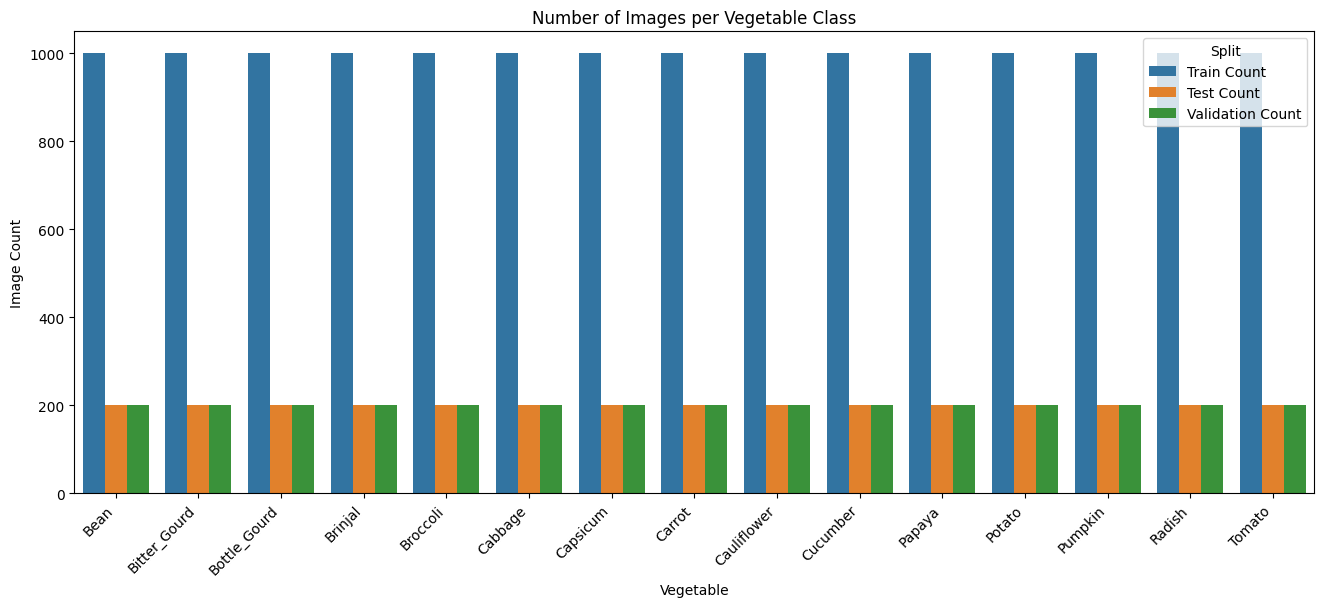

In [60]:
melted_df = summary_df.melt(id_vars="Vegetable", var_name="Split", value_name="Image Count")

plt.figure(figsize=(16, 6))
sns.barplot(data=melted_df, x="Vegetable", y="Image Count", hue="Split")
plt.xticks(rotation=45, ha="right")
plt.title("Number of Images per Vegetable Class")
plt.legend(title="Split")
plt.show()

## Part 6: Image Preprocessing and Augmentation
Use `ImageDataGenerator`.
- Training generator: rescaling, rotation, width shift, height shift, shear, zoom, horizontal flip, validation split
- Validation generator: only rescaling + validation split

In [61]:
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    validation_split=0.2
)

val_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

## Part 7: Load Images Using `flow_from_directory`
`target_size=(224, 224)`, `batch_size=32`, `class_mode="categorical"`, `seed=42`  
Create `train_ds` (`subset="training"`) and `val_ds` (`subset="validation"`).

In [62]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_ds = train_datagen.flow_from_directory(
    train_path,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    subset="training",
    seed=SEED
)

val_ds = val_datagen.flow_from_directory(
    train_path,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    subset="validation",
    seed=SEED
)

print(train_ds.class_indices)

Found 12000 images belonging to 15 classes.
Found 3000 images belonging to 15 classes.
{'Bean': 0, 'Bitter_Gourd': 1, 'Bottle_Gourd': 2, 'Brinjal': 3, 'Broccoli': 4, 'Cabbage': 5, 'Capsicum': 6, 'Carrot': 7, 'Cauliflower': 8, 'Cucumber': 9, 'Papaya': 10, 'Potato': 11, 'Pumpkin': 12, 'Radish': 13, 'Tomato': 14}


## Part 8: Build the CNN Model (Keras Sequential)
- Block 1: Conv2D(32, 3x3, ReLU, input 224x224x3) + MaxPooling2D
- Block 2: Conv2D(64, 3x3, ReLU) + MaxPooling2D
- Block 3: Conv2D(128, 3x3, ReLU) + MaxPooling2D
- Flatten, Dense(512, ReLU), Dropout(0.5), Dense(15, Softmax)

In [63]:
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

model = Sequential([
    # Block 1
    Conv2D(32, (3, 3), activation="relu", input_shape=(224, 224, 3)),
    MaxPooling2D((2, 2)),

    # Block 2
    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    # Block 3
    Conv2D(128, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    Flatten(),
    Dense(512, activation="relu"),
    Dropout(0.5),
    Dense(15, activation="softmax")
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


## Part 9: Compile the Model
Optimizer: Adam | Loss: Categorical Crossentropy | Metric: Accuracy. Print the model summary.

In [64]:
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]

)
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 512)            │    44,302,848 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 15)             │         7,695 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 44,403,791 (169.39 MB)

 Trainable params: 44,403,791 (169.39 MB)

 Non-trainable params: 0 (0.00 B)

## Part 10: Train the Model
Training + validation datasets, max 20 epochs, EarlyStopping (monitor validation loss, patience = 5, restore best weights).

In [ ]:

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=3,
)

Epoch 1/3
 10/375 ━━━━━━━━━━━━━━━━━━━━ 13:46 2s/step - accuracy: 0.0835 - loss: 3.7709

## Part 11: Evaluate the Model
Evaluate on training and validation data. Print Training Accuracy, Validation Accuracy, Training Loss, Validation Loss.

In [ ]:
train_loss, train_acc = model.evaluate(train_ds, verbose=0)
val_loss, val_acc = model.evaluate(val_ds, verbose=0)

print(f"Training Accuracy  : {train_acc:.4f}")
print(f"Validation Accuracy: {val_acc:.4f}")
print(f"Training Loss      : {train_loss:.4f}")
print(f"Validation Loss    : {val_loss:.4f}")

## Part 12: Plot Accuracy and Loss Curves
Training vs Validation Accuracy, and Training vs Validation Loss. Include title, legend, epochs on x-axis, accuracy/loss on y-axis.

In [ ]:
acc = history.history["accuracy"]
val_acc = history.history["val_accuracy"]
loss = history.history["loss"]
val_loss = history.history["val_loss"]

epochs_range = range(1, len(acc) + 1)

plt.figure(figsize=(14, 5))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label="Training Accuracy")
plt.plot(epochs_range, val_acc, label="Validation Accuracy")
plt.title("Training vs Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

# Loss
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label="Training Loss")
plt.plot(epochs_range, val_loss, label="Validation Loss")
plt.title("Training vs Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()